In [1]:
!wget -q https://archive.ics.uci.edu/static/public/321/electricityloaddiagrams20112014.zip
!unzip -o -q electricityloaddiagrams20112014.zip

import pandas as pd
df = pd.read_csv("LD2011_2014.txt", sep=";", decimal=",", index_col=0, parse_dates=True)
print(df.shape)
print(df.index.min(), "to", df.index.max())
print(df.iloc[:3, :4])

(140256, 370)
2011-01-01 00:15:00 to 2015-01-01 00:00:00
                     MT_001  MT_002  MT_003  MT_004
2011-01-01 00:15:00     0.0     0.0     0.0     0.0
2011-01-01 00:30:00     0.0     0.0     0.0     0.0
2011-01-01 00:45:00     0.0     0.0     0.0     0.0


MT_321    0.0
MT_323    0.0
MT_324    0.0
MT_325    0.0
MT_326    0.0
MT_327    0.0
MT_328    0.0
MT_329    0.0
dtype: float64
['MT_321', 'MT_323', 'MT_324', 'MT_325', 'MT_326'] (26304, 5)
train 2012-01-01 00:00:00 to 2014-02-06 03:00:00 18412
val 2014-02-06 04:00:00 to 2014-07-20 13:00:00 3946
test 2014-07-20 14:00:00 to 2014-12-31 23:00:00 3946


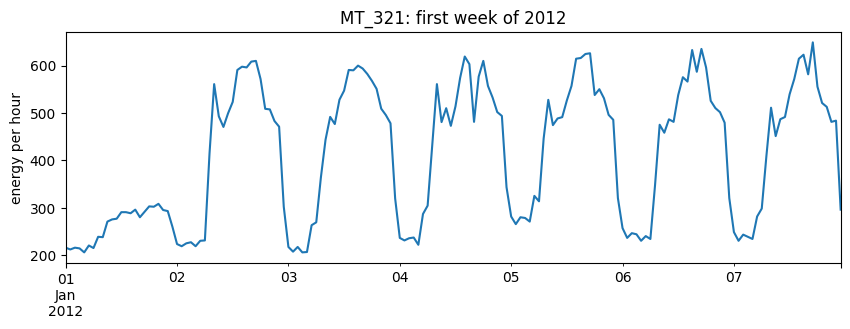

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Turn 15-minute readings into hourly totals (4 readings per hour)
hourly = df.resample("h", closed="right", label="right").sum()

# 2. Keep 2012-2014 only (2011 has many zeros from customers not yet connected)
hourly = hourly.loc["2012-01-01":"2014-12-31"]

# 3. Pick the 5 customers with the fewest zero hours (most complete data)
zero_share = (hourly == 0).mean().sort_values()
print(zero_share.head(8).round(4))
chosen = list(zero_share.index[:5])
data = hourly[chosen]
print(chosen, data.shape)

# 4. Split by TIME: first 70% train, next 15% validation, last 15% test
n = len(data)
train = data.iloc[: int(0.70 * n)]
val   = data.iloc[int(0.70 * n): int(0.85 * n)]
test  = data.iloc[int(0.85 * n):]
for name, part in [("train", train), ("val", val), ("test", test)]:
    print(name, part.index.min(), "to", part.index.max(), len(part))

# 5. Look at one customer for one week
data[chosen[0]].iloc[:24*7].plot(figsize=(10, 3), title=f"{chosen[0]}: first week of 2012")
plt.ylabel("energy per hour")
plt.show()

In [3]:
import numpy as np
import pandas as pd

def mae(y, p):  return float(np.mean(np.abs(y - p)))
def rmse(y, p): return float(np.sqrt(np.mean((y - p) ** 2)))
def mape(y, p): return float(np.mean(np.abs((y - p) / y)) * 100)

rows = []
for cust in chosen:
    s = data[cust]
    # every prediction for hour t uses only values from t-24 or earlier
    preds = {
        "Same hour yesterday":              s.shift(24),
        "Same hour last week":              s.shift(168),
        "Average of same hour, last 7 days": sum(s.shift(24 * k) for k in range(1, 8)) / 7,
    }
    y = s.loc[test.index]
    for name, p in preds.items():
        p = p.loc[test.index]
        rows.append({"Customer": cust, "Method": name,
                     "MAE": mae(y, p), "RMSE": rmse(y, p), "MAPE %": mape(y, p)})

res = pd.DataFrame(rows)
summary = res.groupby("Method")[["MAE", "RMSE", "MAPE %"]].mean().round(2).sort_values("MAPE %")
print(summary)
print()
print(res.pivot(index="Customer", columns="Method", values="MAPE %").round(2))

                                      MAE    RMSE  MAPE %
Method                                                   
Average of same hour, last 7 days  141.78  216.63    6.35
Same hour yesterday                150.15  248.83    6.71
Same hour last week                181.63  267.50    8.06

Method    Average of same hour, last 7 days  Same hour last week  \
Customer                                                           
MT_321                                 6.66                 8.51   
MT_323                                 7.49                 9.39   
MT_324                                 6.03                 7.64   
MT_325                                 5.35                 6.76   
MT_326                                 6.22                 8.01   

Method    Same hour yesterday  
Customer                       
MT_321                   7.41  
MT_323                   7.72  
MT_324                   6.31  
MT_325                   5.23  
MT_326                   6.89  


In [4]:
from xgboost import XGBRegressor

def make_features(s):
    f = pd.DataFrame(index=s.index)
    f["lag_24"] = s.shift(24)
    f["lag_48"] = s.shift(48)
    f["lag_168"] = s.shift(168)
    f["avg_same_hour_7d"] = sum(s.shift(24 * k) for k in range(1, 8)) / 7
    f["mean_prev_day"] = s.shift(24).rolling(24).mean()
    f["hour"] = s.index.hour
    f["dayofweek"] = s.index.dayofweek
    f["month"] = s.index.month
    return f

rows = []
for cust in chosen:
    s = data[cust]
    f = make_features(s).dropna()           # drops the first week (no lags yet)
    tr = f.index.intersection(train.index)
    va = f.index.intersection(val.index)
    te = f.index.intersection(test.index)

    model = XGBRegressor(n_estimators=1000, learning_rate=0.05, max_depth=6,
                         early_stopping_rounds=30, random_state=42, n_jobs=-1)
    model.fit(f.loc[tr], s.loc[tr], eval_set=[(f.loc[va], s.loc[va])], verbose=False)

    y = s.loc[te]
    for name, p in [("XGBoost", model.predict(f.loc[te])),
                    ("Baseline: avg same hour, 7 days", f.loc[te, "avg_same_hour_7d"].values)]:
        rows.append({"Customer": cust, "Method": name,
                     "MAE": mae(y.values, p), "RMSE": rmse(y.values, p),
                     "MAPE %": mape(y.values, p)})
    print("done:", cust, "| trees used:", model.best_iteration + 1)

res2 = pd.DataFrame(rows)
print(res2.groupby("Method")[["MAE", "RMSE", "MAPE %"]].mean().round(2))
print()
print(res2.pivot(index="Customer", columns="Method", values="MAPE %").round(2))

done: MT_321 | trees used: 173
done: MT_323 | trees used: 108
done: MT_324 | trees used: 126
done: MT_325 | trees used: 77
done: MT_326 | trees used: 117
                                    MAE    RMSE  MAPE %
Method                                                 
Baseline: avg same hour, 7 days  141.78  216.63    6.35
XGBoost                          132.86  203.05    6.00

Method    Baseline: avg same hour, 7 days  XGBoost
Customer                                          
MT_321                               6.66     6.33
MT_323                               7.49     7.02
MT_324                               6.03     5.83
MT_325                               5.35     4.69
MT_326                               6.22     6.12


In [6]:
def make_features(s, h=24):
    """All features use only data from h hours earlier or before."""
    f = pd.DataFrame(index=s.index)
    f["lag_base"]    = s.shift(h)
    f["lag_plus24"]  = s.shift(h + 24)
    f["lag_plus168"] = s.shift(168 if h < 168 else h + 168)
    f["avg_same_hour_7d"] = sum(s.shift(h + 24 * k) for k in range(7)) / 7
    f["mean_prev_day"]    = s.shift(h).rolling(24).mean()
    f["hour"] = s.index.hour
    f["dayofweek"] = s.index.dayofweek
    f["month"] = s.index.month
    return f

def evaluate(h, drop=()):
    out = []
    for cust in chosen:
        s = data[cust]
        f = make_features(s, h).dropna()
        tr = f.index.intersection(train.index)
        va = f.index.intersection(val.index)
        te = f.index.intersection(test.index)
        cols = [c for c in f.columns if c not in drop]
        m = XGBRegressor(n_estimators=1000, learning_rate=0.05, max_depth=6,
                         early_stopping_rounds=30, random_state=42, n_jobs=-1)
        m.fit(f.loc[tr, cols], s.loc[tr], eval_set=[(f.loc[va, cols], s.loc[va])], verbose=False)
        y = s.loc[te].values
        p = m.predict(f.loc[te, cols])
        b = f.loc[te, "avg_same_hour_7d"].values
        out.append([mae(y, p), mape(y, p), mae(y, b), mape(y, b)])
    return np.mean(out, axis=0)

# Part A: forecast horizon (all features)
rows = []
for h in [24, 168]:
    mm, mp, bm, bp = evaluate(h)
    rows.append({"Horizon": f"{h} h ahead", "Baseline MAE": bm, "XGBoost MAE": mm,
                 "Baseline MAPE %": bp, "XGBoost MAPE %": mp})
print(pd.DataFrame(rows).round(2))

# Part B: ablation at 24 h (remove one feature group at a time)
groups = {
    "nothing removed": (),
    "lag features": ("lag_base", "lag_plus24", "lag_plus168"),
    "rolling averages": ("avg_same_hour_7d", "mean_prev_day"),
    "calendar (hour, weekday, month)": ("hour", "dayofweek", "month"),
}
rows = []
for name, drop in groups.items():
    mm, mp, _, _ = evaluate(24, drop)
    rows.append({"Removed": name, "MAE": mm, "MAPE %": mp})
print(pd.DataFrame(rows).round(2))

       Horizon  Baseline MAE  XGBoost MAE  Baseline MAPE %  XGBoost MAPE %
0   24 h ahead        141.78       132.86             6.35            6.00
1  168 h ahead        164.40       166.65             7.59            7.38
                           Removed     MAE  MAPE %
0                  nothing removed  132.86    6.00
1                     lag features  143.52    6.49
2                 rolling averages  135.81    6.13
3  calendar (hour, weekday, month)  137.22    6.15


check, XGB MAE (should be ~132.86): 132.86
hour    0    1    2    3    4    5    6    7    8    9   ...   14   15   16  \
ape_x  6.2  6.5  7.1  6.8  7.2  6.9  7.4  6.9  6.1  5.1  ...  5.8  5.5  5.9   
ape_b  6.7  6.9  7.8  7.5  7.3  6.9  6.7  6.9  6.1  5.1  ...  6.1  6.0  6.4   

hour    17   18   19   20   21   22   23  
ape_x  6.0  5.8  5.5  5.3  4.9  4.8  5.4  
ape_b  6.5  6.4  6.2  6.0  5.6  5.4  5.9  

[2 rows x 24 columns]
dow      0    1    2    3    4    5    6
ape_x  5.2  6.0  6.3  8.5  5.3  5.5  5.2
ape_b  5.9  6.3  6.6  9.0  5.5  5.5  5.7
month   7    8    9    10   11    12
ape_x  4.8  5.0  4.4  5.1  5.6  10.2
ape_b  4.8  5.4  4.8  5.7  6.0  10.3
            ape_x  ape_b
2014-12-25   79.1   81.0
2014-12-31   16.2   18.2
2014-12-24   14.9   16.5
2014-12-27   11.5    9.8
2014-12-30    9.2   10.5
2014-12-23    9.1    7.2
2014-12-16    8.8    9.3
2014-12-19    8.3    7.6


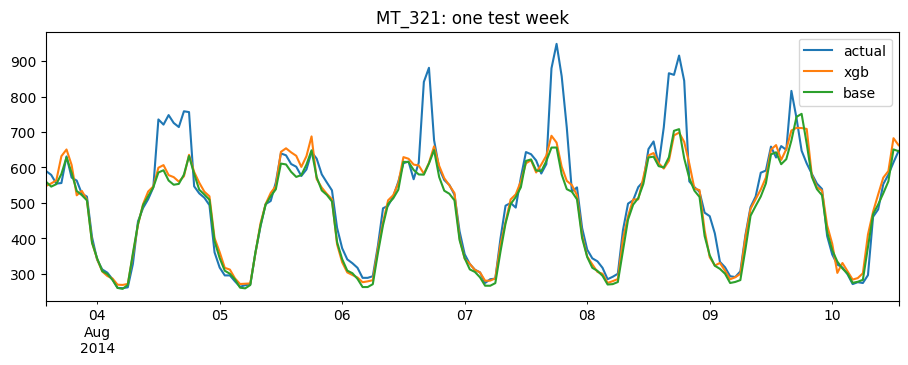

In [7]:
import matplotlib.pyplot as plt

def make_features(s, h=24):
    f = pd.DataFrame(index=s.index)
    f["lag_base"]    = s.shift(h)
    f["lag_plus24"]  = s.shift(h + 24)
    f["lag_plus168"] = s.shift(168 if h < 168 else h + 168)
    f["avg_same_hour_7d"] = sum(s.shift(h + 24 * k) for k in range(7)) / 7
    f["mean_prev_day"]    = s.shift(h).rolling(24).mean()
    f["hour"], f["dayofweek"], f["month"] = s.index.hour, s.index.dayofweek, s.index.month
    return f

frames = []
for cust in chosen:
    s = data[cust]
    f = make_features(s).dropna()
    tr, va, te = (f.index.intersection(x.index) for x in (train, val, test))
    m = XGBRegressor(n_estimators=1000, learning_rate=0.05, max_depth=6,
                     early_stopping_rounds=30, random_state=42, n_jobs=-1)
    m.fit(f.loc[tr], s.loc[tr], eval_set=[(f.loc[va], s.loc[va])], verbose=False)
    out = pd.DataFrame({"actual": s.loc[te], "xgb": m.predict(f.loc[te]),
                        "base": f.loc[te, "avg_same_hour_7d"], "cust": cust})
    frames.append(out)
pred = pd.concat(frames)
print("check, XGB MAE (should be ~132.86):", round(mae(pred.actual.values, pred.xgb.values), 2))

pred["ape_x"] = (pred.xgb - pred.actual).abs() / pred.actual * 100
pred["ape_b"] = (pred.base - pred.actual).abs() / pred.actual * 100
pred["hour"], pred["dow"], pred["month"] = pred.index.hour, pred.index.dayofweek, pred.index.month

print(pred.groupby("hour")[["ape_x", "ape_b"]].mean().round(1).T)
print(pred.groupby("dow")[["ape_x", "ape_b"]].mean().round(1).T)
print(pred.groupby("month")[["ape_x", "ape_b"]].mean().round(1).T)

daily = pred.groupby(pred.index.date)[["ape_x", "ape_b"]].mean().sort_values("ape_x", ascending=False)
print(daily.head(8).round(1))

c = chosen[0]
w = pred[pred.cust == c].iloc[24 * 14: 24 * 21]
w[["actual", "xgb", "base"]].plot(figsize=(11, 3.5), title=f"{c}: one test week")
plt.show()

In [8]:
!pip install -q holidays
import holidays
from datetime import timedelta

hol = set(holidays.Portugal(years=[2012, 2013, 2014, 2015]).keys())

def make_features_h(s, h=24):
    f = make_features(s, h)
    d = pd.Series(s.index.date, index=s.index)
    f["is_holiday"] = d.isin(hol).astype(int)
    f["holiday_tomorrow"] = d.map(lambda x: (x + timedelta(days=1)) in hol).astype(int)
    f["holiday_yesterday"] = d.map(lambda x: (x - timedelta(days=1)) in hol).astype(int)
    return f

def run(feat_fn):
    frames = []
    for cust in chosen:
        s = data[cust]
        f = feat_fn(s).dropna()
        tr, va, te = (f.index.intersection(x.index) for x in (train, val, test))
        m = XGBRegressor(n_estimators=1000, learning_rate=0.05, max_depth=6,
                         early_stopping_rounds=30, random_state=42, n_jobs=-1)
        m.fit(f.loc[tr], s.loc[tr], eval_set=[(f.loc[va], s.loc[va])], verbose=False)
        frames.append(pd.DataFrame({"actual": s.loc[te], "xgb": m.predict(f.loc[te]),
                                    "base": f.loc[te, "avg_same_hour_7d"]}))
    return pd.concat(frames)

p0 = run(make_features)      # without holiday flags
p1 = run(make_features_h)    # with holiday flags

dates = pd.Series(p0.index.date)
flag = (dates.isin(hol)
        | dates.map(lambda x: (x + timedelta(days=1)) in hol)
        | dates.map(lambda x: (x - timedelta(days=1)) in hol)).values
y = p0.actual.values

def rep(name, p):
    return {"Method": name,
            "MAE all": mae(y, p), "MAPE all": mape(y, p),
            "MAPE normal days": mape(y[~flag], p[~flag]),
            "MAPE holiday-period": mape(y[flag], p[flag])}

rows = [rep("Baseline (7-day avg)", p0.base.values),
        rep("XGBoost", p0.xgb.values),
        rep("XGBoost + holiday flags", p1.xgb.values)]
print(pd.DataFrame(rows).round(2))
print("holiday-period hours per customer:", flag.sum() // len(chosen))

                    Method  MAE all  MAPE all  MAPE normal days  \
0     Baseline (7-day avg)   141.78      6.35              5.71   
1                  XGBoost   132.86      6.00              5.38   
2  XGBoost + holiday flags   133.50      6.02              5.38   

   MAPE holiday-period  
0                16.16  
1                15.55  
2                15.87  
holiday-period hours per customer: 240
